# 02 — Model training

This notebook trains the two Stage 2 models and compares them with the Stage 1 baseline.

1. **Logistic regression**: form and league-table difference features → P(home win), P(draw), P(away win) directly.
2. **Poisson regression**: predicts home goals and away goals separately, then turns those into H/D/A
   probabilities via a scoreline grid (P(2–1), P(1–1), …).
3. **Pick the regularisation** for each model on one validation season.
4. **First check** on the 2025/26 season, which was not used for anything above.
5. **Save** the final models to `models/` for notebooks 03 and 04.

The score used here is **log loss**: the average of −log(probability given to what actually happened).
Lower is better. A model that always says 1/3–1/3–1/3 scores log(3) ≈ 1.099.
Proper evaluation (Brier score, RPS, calibration, walk-forward backtest) is Stage 3.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.data import load_processed
from src.evaluation import CLASSES, log_loss
from src.features import build_fixture_features, drop_incomplete
from src.models import (LOGISTIC_FEATURES, POISSON_FEATURES, HistoricalBaseline, LogisticModel,
                        PoissonModel, load_model, save_model)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

## 0. Run the tests first

In [2]:
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no"], cwd=PROJECT_ROOT,
                        capture_output=True, text=True)
print(result.stdout[-1500:] or result.stderr[-1500:])

........................................................................ [ 93%]
.....                                                                    [100%]
77 passed in 3.88s



## 1. Data and time-based splits

Load the matches saved by notebook 01 and keep only those where every feature exists
(teams need 5 earlier matches). Splits are **by date, never random**, because a random split would
let the model train on matches played after the ones it is tested on.

| Split | Seasons | Used for |
|---|---|---|
| tune-train | 2016/17 – 2023/24 | fitting while choosing regularisation |
| tune-validation | 2024/25 | choosing regularisation |
| check | 2025/26 | one honest first look, touched once |
| current | 2026/27 | not used here (predictions are Stage 4) |

In [3]:
features = load_processed()
complete = drop_incomplete(features)
played = complete[complete["result"].isin(CLASSES)]
print(f"{len(played)} complete matches, {played['date'].min().date()} to {played['date'].max().date()}")

TUNE_SPLIT = pd.Timestamp("2024-07-01")
CHECK_SPLIT = pd.Timestamp("2025-07-01")
CURRENT_SPLIT = pd.Timestamp("2026-07-01")

tune_train = played[played["date"] < TUNE_SPLIT]
tune_val = played[(played["date"] >= TUNE_SPLIT) & (played["date"] < CHECK_SPLIT)]
train = played[played["date"] < CHECK_SPLIT]
check = played[(played["date"] >= CHECK_SPLIT) & (played["date"] < CURRENT_SPLIT)]

pd.DataFrame({
    "matches": [len(tune_train), len(tune_val), len(train), len(check)],
    "from": [d["date"].min().date() for d in (tune_train, tune_val, train, check)],
    "to": [d["date"].max().date() for d in (tune_train, tune_val, train, check)],
}, index=["tune-train", "tune-validation", "train (final)", "check 2025/26"])

3710 complete matches, 2016-09-30 to 2026-10-11


,matches,from,to
tune-train,2902,2016-09-30,2024-05-19
tune-validation,374,2024-08-16,2025-05-25
train (final),3276,2016-09-30,2025-05-25
check 2025/26,380,2025-08-15,2026-05-24


## 2. Choose regularisation

Both models are regularised: large coefficients are penalised, which stops the model from chasing noise.
The form features are strongly correlated (xG, goals and points all measure "how good recently"),
so without some penalty the coefficients can become unstable.

- Logistic: `C` — **smaller C = stronger penalty**.
- Poisson: `alpha` — **larger alpha = stronger penalty**.

Each value is fitted on 2016/17–2023/24 and scored on 2024/25.

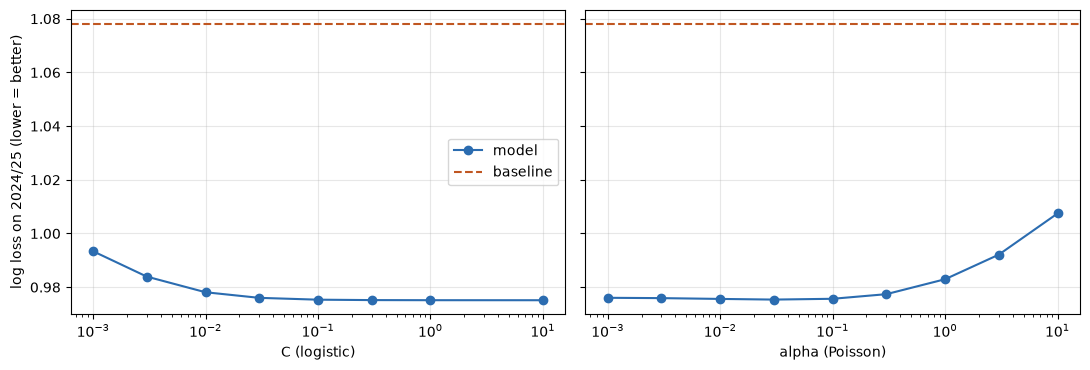

Baseline: 1.0781
Best C:     10.0   log loss 0.9751
Best alpha: 0.03   log loss 0.9754


In [4]:
baseline_tune = log_loss(tune_val["result"],
                         HistoricalBaseline().fit(tune_train["result"]).predict_proba(len(tune_val)))

C_GRID = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 10]
ALPHA_GRID = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]

logistic_scores = pd.Series(
    {C: log_loss(tune_val["result"], LogisticModel(C=C).fit(tune_train).predict_proba(tune_val)) for C in C_GRID},
    name="log loss")
poisson_scores = pd.Series(
    {a: log_loss(tune_val["result"], PoissonModel(alpha=a).fit(tune_train).predict_proba(tune_val)) for a in ALPHA_GRID},
    name="log loss")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, scores, label in [(axes[0], logistic_scores, "C (logistic)"), (axes[1], poisson_scores, "alpha (Poisson)")]:
    ax.plot(scores.index, scores.values, marker="o", color="#2b6cb0", label="model")
    ax.axhline(baseline_tune, color="#c05621", ls="--", label="baseline")
    ax.set_xscale("log")
    ax.set_xlabel(label)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("log loss on 2024/25 (lower = better)")
axes[0].legend()
plt.tight_layout()
plt.show()

print(f"Baseline: {baseline_tune:.4f}")
print(f"Best C:     {logistic_scores.idxmin():<6} log loss {logistic_scores.min():.4f}")
print(f"Best alpha: {poisson_scores.idxmin():<6} log loss {poisson_scores.min():.4f}")

The curves are **flat** near the best value, so the exact choice barely matters. The values below
(also the defaults in `src/models.py`) sit in that flat region. A single season is a noisy
yardstick, so it would be overfitting to chase the 4th decimal place.

In [5]:
C = 0.1
ALPHA = 0.1
print(f"Chosen: C = {C} (log loss {logistic_scores[C]:.4f}), alpha = {ALPHA} (log loss {poisson_scores[ALPHA]:.4f})")

Chosen: C = 0.1 (log loss 0.9753), alpha = 0.1 (log loss 0.9757)


## 3. Fit on everything before 2025/26

Now refit with the chosen values on all seasons 2016/17–2024/25.

In [6]:
baseline = HistoricalBaseline().fit(train["result"])
logistic = LogisticModel(C=C).fit(train)
poisson_model = PoissonModel(alpha=ALPHA).fit(train)
print(f"Trained on {logistic.n_matches_} matches.")

Trained on 3276 matches.


### What did the logistic model learn?

Coefficients per outcome on **standardised** features (1 unit = 1 standard deviation), so their sizes
can be compared. A positive number for H means "a larger value of this feature makes a home win more likely".
With correlated features, read the overall pattern rather than any single number.

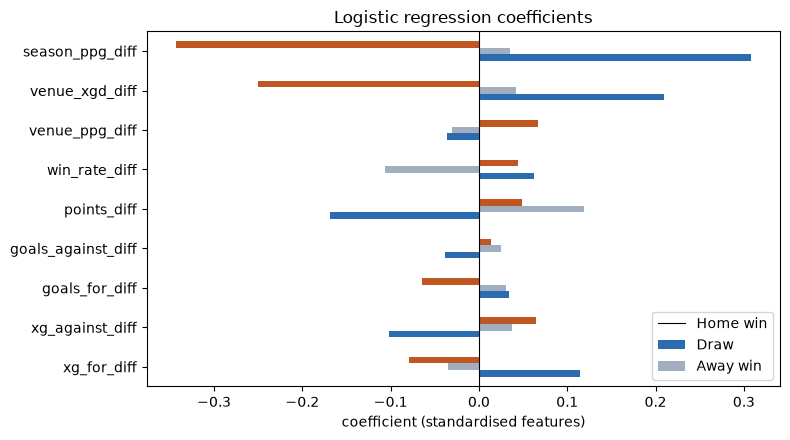

,xg_for_diff,xg_against_diff,goals_for_diff,goals_against_diff,points_diff,win_rate_diff,venue_ppg_diff,venue_xgd_diff,season_ppg_diff
H,0.115,-0.102,0.034,-0.038,-0.168,0.063,-0.037,0.209,0.308
D,-0.035,0.037,0.031,0.025,0.119,-0.107,-0.030,0.042,0.035
A,-0.079,0.065,-0.064,0.014,0.049,0.044,0.067,-0.251,-0.344


In [7]:
coefs = logistic.coefficients()
ax = coefs.T.plot(kind="barh", figsize=(8, 4.5), color=["#2b6cb0", "#a0aec0", "#c05621"])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("coefficient (standardised features)")
ax.legend(["Home win", "Draw", "Away win"], loc="lower right")
ax.set_title("Logistic regression coefficients")
plt.tight_layout()
plt.show()
coefs.round(3)

### Do the Poisson expected goals look sensible?

Averaged over the training matches, predicted goals should be close to actual goals, and home teams
should be expected to score more than away teams.

In [8]:
mu = poisson_model.predict_goals(train)
pd.DataFrame({
    "predicted (avg)": [mu["home_mu"].mean(), mu["away_mu"].mean()],
    "actual (avg)": [train["home_goals"].mean(), train["away_goals"].mean()],
    "predicted min": [mu["home_mu"].min(), mu["away_mu"].min()],
    "predicted max": [mu["home_mu"].max(), mu["away_mu"].max()],
}, index=["home goals", "away goals"]).round(2)

,predicted (avg),actual (avg),predicted min,predicted max
home goals,1.56,1.56,0.59,3.76
away goals,1.29,1.29,0.48,3.35


## 4. First check on 2025/26

These 2025/26 matches were not used to fit or tune anything. This is one season and one fixed model,
so treat it as a sanity check, not the final verdict. Stage 3 refits the models through time
(walk-forward) and adds Brier score, RPS and calibration.

**Accuracy** (how often the most likely outcome happened) is shown for intuition only. It ignores
how confident the model was, which is what the project cares about.

In [9]:
predictions = {
    "Baseline": baseline.predict_proba(len(check)),
    "Logistic": logistic.predict_proba(check),
    "Poisson": poisson_model.predict_proba(check),
}
actual_idx = check["result"].map(CLASSES.index).to_numpy()
summary = pd.DataFrame({
    "log loss": {name: log_loss(check["result"], p) for name, p in predictions.items()},
    "accuracy": {name: (p.argmax(axis=1) == actual_idx).mean() for name, p in predictions.items()},
    "avg P(draw)": {name: p[:, 1].mean() for name, p in predictions.items()},
})
summary.loc["Uniform 1/3"] = [np.log(3), np.nan, 1 / 3]
print(f"2025/26: {len(check)} matches, actual draw share {(check['result'] == 'D').mean():.3f}")
summary.round(4)

2025/26: 380 matches, actual draw share 0.274


,log loss,accuracy,avg P(draw)
Baseline,1.0853,0.4263,0.2268
Logistic,1.0413,0.4632,0.2351
Poisson,1.0434,0.4763,0.2354
Uniform 1/3,1.0986,NaN,0.3333


**What to look for:** both models should have clearly lower log loss than the baseline. Note how the
models almost never pick a draw as the most likely outcome; draws are hard to predict and that is normal.

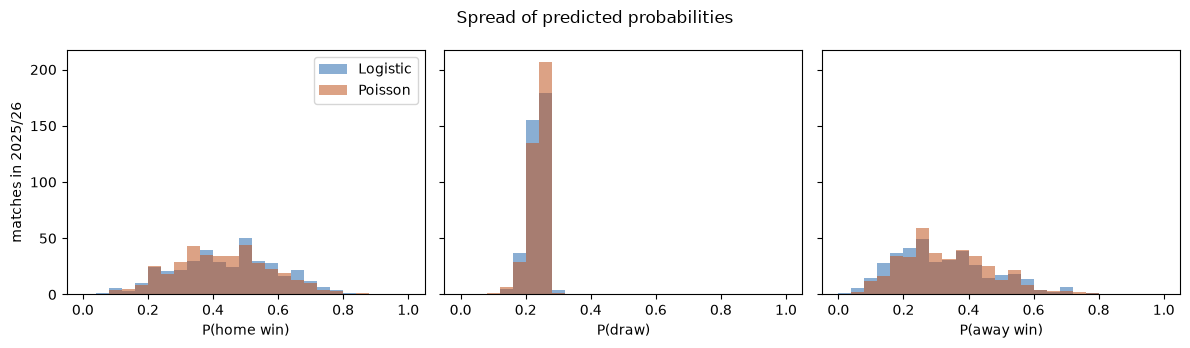

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, (j, label) in zip(axes, enumerate(["P(home win)", "P(draw)", "P(away win)"])):
    for name, color in [("Logistic", "#2b6cb0"), ("Poisson", "#c05621")]:
        ax.hist(predictions[name][:, j], bins=25, range=(0, 1), alpha=0.55, color=color, label=name)
    ax.set_xlabel(label)
axes[0].set_ylabel("matches in 2025/26")
axes[0].legend()
plt.suptitle("Spread of predicted probabilities")
plt.tight_layout()
plt.show()

### One example match

The most recent 2025/26 match, with the probabilities from each model.

In [11]:
example = check.iloc[[-1]]
row = example.iloc[0]
mu_ex = poisson_model.predict_goals(example).iloc[0]
print(f"{row['home_team']} vs {row['away_team']} on {row['date'].date()}: "
      f"actual {int(row['home_goals'])}-{int(row['away_goals'])} ({row['result']})")
print(f"Poisson expected goals: {mu_ex['home_mu']:.2f} - {mu_ex['away_mu']:.2f}")
pd.DataFrame({name: p[-1] for name, p in predictions.items()}, index=["Home win", "Draw", "Away win"]).round(3)

West Ham vs Leeds on 2026-05-24: actual 3-0 (H)
Poisson expected goals: 1.34 - 1.43


,Baseline,Logistic,Poisson
Home win,0.449,0.357,0.354
Draw,0.227,0.242,0.254
Away win,0.324,0.401,0.392


## 5. Save the final models

For predicting upcoming matches (notebook 04) the models should know the most recent form, so the saved
versions are refitted on **every complete played match**, including 2025/26 and 2026/27 so far.
The backtest in notebook 03 does **not** use these files: it refits before every matchday with
`fit_*_before(date)` so it never sees the future.

In [12]:
final_baseline = HistoricalBaseline().fit(played["result"])
final_logistic = LogisticModel(C=C).fit(played)
final_poisson = PoissonModel(alpha=ALPHA).fit(played)

for name, model in [("baseline", final_baseline), ("logistic", final_logistic), ("poisson", final_poisson)]:
    path = save_model(model, name)
    print(f"Saved {name:<9} ({model.n_matches_} matches) -> {path.relative_to(PROJECT_ROOT)}")
print(f"Training data up to {played['date'].max().date()}")

Saved baseline  (3710 matches) -> models/baseline.joblib
Saved logistic  (3710 matches) -> models/logistic.joblib
Saved poisson   (3710 matches) -> models/poisson.joblib
Training data up to 2026-10-11


Reload one saved model and check it gives identical predictions.

In [13]:
reloaded = load_model("logistic")
same = np.array_equal(reloaded.predict_proba(check), final_logistic.predict_proba(check))
print("Reloaded model gives identical predictions:", same)

Reloaded model gives identical predictions: True
